In [1]:
setwd('/lustre/orion/syb111/proj-shared/Personal/abeyratnecr/switchgrass/sub_proj/snp2geneLD')
getwd()

[1] "/lustre/orion/syb111/proj-shared/Personal/abeyratnecr/switchgrass/sub_proj/snp2geneLD"

In [2]:
rm(list=ls())

# load tidyverse for binning function
suppressPackageStartupMessages(library(tidyverse))
suppressPackageStartupMessages(library(pracma))
library(magrittr)

Warning message in system("timedatectl", intern = TRUE):
“running command 'timedatectl' had status 1”

Attaching package: ‘magrittr’


The following objects are masked from ‘package:pracma’:

    and, mod, or


The following object is masked from ‘package:purrr’:

    set_names


The following object is masked from ‘package:tidyr’:

    extract




In [7]:
coords = read.table('./pw_ld/1000000_500000.bed', header=FALSE)
contig_name='Chr01K'
coords_ = coords %>% filter(str_detect(V1, contig_name))
dim(coords_)
tail(coords_, 20)

[1] 114   3

,V1,V2,V3
,<chr>,<int>,<int>
95,Chr01K,47000000,48000000
96,Chr01K,47500000,48500000
97,Chr01K,48000000,49000000
98,Chr01K,48500000,49500000
99,Chr01K,49000000,50000000
100,Chr01K,49500000,50500000
101,Chr01K,50000000,51000000
102,Chr01K,50500000,51500000
103,Chr01K,51000000,52000000


In [9]:
i=1
snpld_filename <- paste0('./pw_ld/', coords_$V1[i], '_', coords_$V2[i], '_', coords_$V3[i], '.ld')
ld<-read.table(snpld_filename,header=T)
head(ld)

,CHR_A,BP_A,SNP_A,CHR_B,BP_B,SNP_B,R2
,<int>,<int>,<chr>,<int>,<int>,<chr>,<dbl>
1,1,1119,1_1119,1,1120,1_1120,0.003544510
2,1,1119,1_1119,1,1137,1_1137,0.002432440
3,1,1119,1_1119,1,1166,1_1166,0.004412550
4,1,1119,1_1119,1,1168,1_1168,0.000513051
5,1,1119,1_1119,1,1174,1_1174,0.001180330
6,1,1119,1_1119,1,1176,1_1176,0.055366900


In [12]:
snpa <- ld$SNP_A %>% unique() 
snpb <- ld$SNP_A %>% unique() 
uniq_snps <- c(snpa, snpb) %>% unique() %>% length()
uniq_snps

[1] 24442

In [81]:
missing_fns <- NULL
gw_ld <- NULL
for (i in 1:nrow(coords_)) { # 
    snpld_filename <- paste0('./pw_ld2/', coords_$V1[i], '_', coords_$V2[i], '_', coords_$V3[i], '.ld')
    if (file.exists(snpld_filename)) {
        
        ld<-read.table(snpld_filename,header=T)
        median_r2 = median(ld$R2)
        mid_pos = mean(c(coords_$V2[i], coords_$V3[i]))
        gw_ld <- rbind(gw_ld, c(
            Chr=coords_$V1[i],
            mid_pos=mid_pos,
            median_r2=median_r2
        ))
    } else {
        missing_fns <- rbind(missing_fns, snpld_filename)
    }
}

In [75]:
missing_fns %>% length()

[1] 0

In [76]:
gw_ld %<>% as.data.frame()
gw_ld$median_r2 <- gw_ld$median_r2 %>% as.numeric()
gw_ld$mid_pos <- gw_ld$mid_pos %>% as.numeric()
head(gw_ld)

,Chr,mid_pos,median_r2
,<chr>,<dbl>,<dbl>
1,Chr01N,250000,0.003582000
2,Chr01N,500000,0.003171255
3,Chr01N,750000,0.003325785
4,Chr01N,1000000,0.003317605
5,Chr01N,1250000,0.002992690
6,Chr01N,1500000,0.002905430


In [77]:
gw_ld %>% pull(Chr) %>% unique()

[1] "Chr01N"

In [78]:
dim(gw_ld)
str(gw_ld)
tail(gw_ld)

[1] 269   3

'data.frame':	269 obs. of  3 variables:
 $ Chr      : chr  "Chr01N" "Chr01N" "Chr01N" "Chr01N" ...
 $ mid_pos  : num  250000 500000 750000 1000000 1250000 1500000 1750000 2000000 2250000 2500000 ...
 $ median_r2: num  0.00358 0.00317 0.00333 0.00332 0.00299 ...


,Chr,mid_pos,median_r2
,<chr>,<dbl>,<dbl>
264,Chr01N,66000000,0.003406140
265,Chr01N,66250000,0.003224970
266,Chr01N,66500000,0.003113665
267,Chr01N,66750000,0.003141990
268,Chr01N,66875830,0.003158650
269,Chr01N,67000830,0.016037500


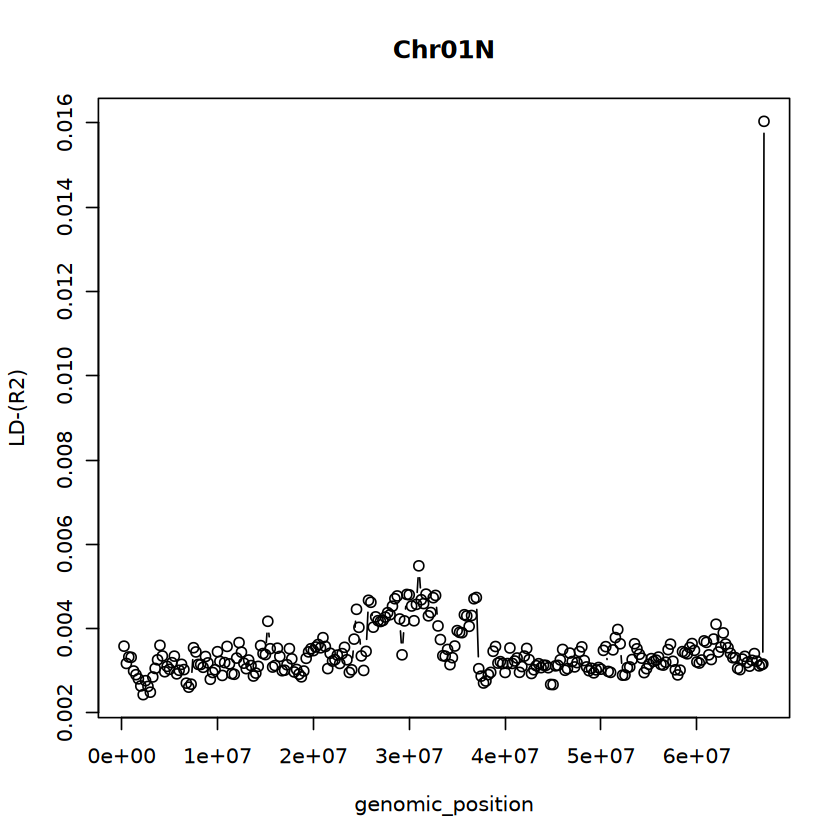

In [79]:
plot(gw_ld$mid_pos, gw_ld$median_r2, type='b', xlab='genomic_position', ylab='LD-(R2)', main=contig_name)

In [ ]:
# END